In [1]:
        # Importing relevant packages.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.metrics import mean_squared_error, r2_score

!pip install xgboost
from xgboost import XGBRegressor

import os
os.getcwd()

'C:\\Users\\primo'

In [2]:
        # Obtaining cancer data csv.

df = pd.read_csv('cancer_data.csv')
cancer_df = df.copy()

print(cancer_df.head(4))

  Cancer_Type ICD_10_Code Gender Age_Group Age_Standardized  \
0        Anus         C21    Men      True            15-99   
1        Anus         C21    Men     False            15-99   
2        Anus         C21    Men       NaN            15-44   
3        Anus         C21    Men       NaN            45-54   

   Number_Of_Patients  One_Year_Survival_Percentage  \
0                3429                          79.8   
1                3429                          81.6   
2                 261                          91.6   
3                 579                          91.5   

   First_Year_Lower_95pct_Confidence_Intervals  \
0                                         78.2   
1                                         80.1   
2                                         87.8   
3                                         89.1   

   First_Year_Upper_95pct_Confidence_Intervals  Five_Year_Survival_Percentage  \
0                                         81.5                           53.

In [3]:
        # Cancer data. pre-EDA

print(cancer_df.shape)
print(cancer_df.columns)
print(cancer_df.describe())

(519, 15)
Index(['Cancer_Type', 'ICD_10_Code', 'Gender', 'Age_Group', 'Age_Standardized',
       'Number_Of_Patients', 'One_Year_Survival_Percentage',
       'First_Year_Lower_95pct_Confidence_Intervals',
       'First_Year_Upper_95pct_Confidence_Intervals',
       'Five_Year_Survival_Percentage',
       'Fifth_Year_Lower_95pct_Confidence_Intervals',
       'Fifth_Year_Upper_95pct_Confidence_Intervals',
       'Ten_Year_Survival_Percentage',
       'Tenth_Year_Lower_95pct_Confidence_Intervals',
       'Tenth_Year_Upper_95pct_Confidence_Intervals'],
      dtype='object')
       Number_Of_Patients  One_Year_Survival_Percentage  \
count          519.000000                    493.000000   
mean         25907.192678                     70.938742   
std          50267.646679                     21.979308   
min             44.000000                      6.100000   
25%           2851.000000                     54.300000   
50%           8897.000000                     77.700000   
75%       

In [4]:
        # Cancer data. Data Cleaning: dropping columns, creating new features, handling missing values and outliers

    ## Creating CI Width, and eliminating non-important features to avoid data leakage

print(cancer_df.columns.tolist())

cancer_df["First_Year_CI_Width"] = (cancer_df['First_Year_Upper_95pct_Confidence_Intervals'] - cancer_df['First_Year_Lower_95pct_Confidence_Intervals'])
cancer_df["Fifth_Year_CI_Width"] = (cancer_df['Fifth_Year_Upper_95pct_Confidence_Intervals'] - cancer_df['Fifth_Year_Lower_95pct_Confidence_Intervals'])
cancer_df["Tenth_Year_CI_Width"] = (cancer_df['Tenth_Year_Upper_95pct_Confidence_Intervals'] - cancer_df['Tenth_Year_Lower_95pct_Confidence_Intervals'])

cancer_df_clean = cancer_df.drop(columns=['First_Year_Lower_95pct_Confidence_Intervals',
                        'First_Year_Upper_95pct_Confidence_Intervals',
                        'Fifth_Year_Lower_95pct_Confidence_Intervals',
                        'Fifth_Year_Upper_95pct_Confidence_Intervals',
                        'Tenth_Year_Lower_95pct_Confidence_Intervals',
                        'Tenth_Year_Upper_95pct_Confidence_Intervals',
                        'Five_Year_Survival_Percentage',
                        'One_Year_Survival_Percentage',
                        'ICD_10_Code'], errors='ignore')

print(cancer_df_clean.isna().sum())
print(cancer_df_clean.dtypes)

    ## Imputing numeric values with th median, and categorical values with the mode

num_cols = cancer_df_clean.select_dtypes(include='number').columns
cat_cols = cancer_df_clean.select_dtypes(exclude='number').columns

for col in num_cols:
    if cancer_df_clean[col].isna().any(): cancer_df_clean[col] = cancer_df_clean[col].fillna(cancer_df_clean[col].median())

for col in cat_cols:
    if cancer_df_clean[col].isna().any(): cancer_df_clean[col] = cancer_df_clean[col].fillna(cancer_df_clean[col].mode().iloc[0])

print(cancer_df_clean.isna().sum().sort_values(ascending=False))

    ## Imputing/Dropping outliers with IQR

outliers_list = []
for cancer_type in cancer_df_clean['Cancer_Type'].unique():
    subset = cancer_df_clean[cancer_df_clean['Cancer_Type'] == cancer_type]
    q1 = subset['Ten_Year_Survival_Percentage'].quantile(0.25)
    q3 = subset['Ten_Year_Survival_Percentage'].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    
    outliers = subset[(subset['Ten_Year_Survival_Percentage'] < lower) | 
                      (subset['Ten_Year_Survival_Percentage'] > upper)]
    outliers_list.append(outliers)

all_outliers = pd.concat(outliers_list)
cancer_df_clean = cancer_df_clean.drop(all_outliers.index)

['Cancer_Type', 'ICD_10_Code', 'Gender', 'Age_Group', 'Age_Standardized', 'Number_Of_Patients', 'One_Year_Survival_Percentage', 'First_Year_Lower_95pct_Confidence_Intervals', 'First_Year_Upper_95pct_Confidence_Intervals', 'Five_Year_Survival_Percentage', 'Fifth_Year_Lower_95pct_Confidence_Intervals', 'Fifth_Year_Upper_95pct_Confidence_Intervals', 'Ten_Year_Survival_Percentage', 'Tenth_Year_Lower_95pct_Confidence_Intervals', 'Tenth_Year_Upper_95pct_Confidence_Intervals']
Cancer_Type                       0
Gender                            0
Age_Group                       381
Age_Standardized                  0
Number_Of_Patients                0
Ten_Year_Survival_Percentage    125
First_Year_CI_Width              26
Fifth_Year_CI_Width              40
Tenth_Year_CI_Width             125
dtype: int64
Cancer_Type                      object
Gender                           object
Age_Group                        object
Age_Standardized                 object
Number_Of_Patients          

C:\Users\primo\AppData\Local\Temp\ipykernel_18916\4165583493.py:33: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  if cancer_df_clean[col].isna().any(): cancer_df_clean[col] = cancer_df_clean[col].fillna(cancer_df_clean[col].mode().iloc[0])


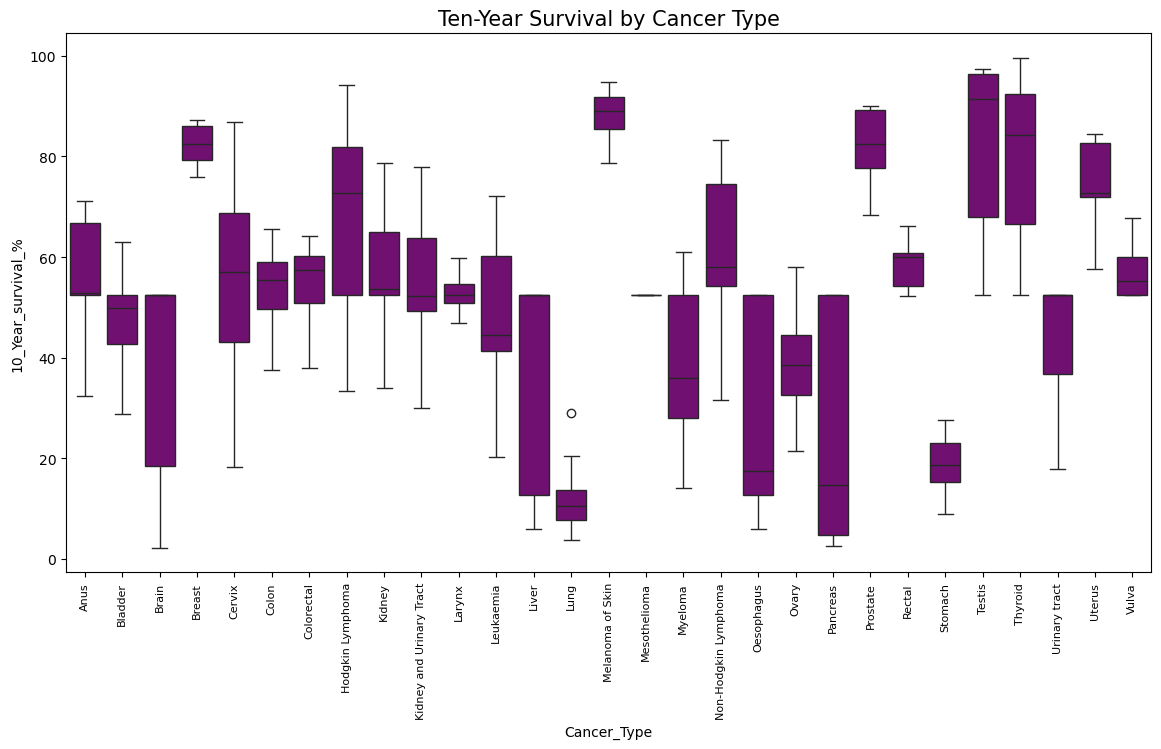

In [5]:
        # Cancer type vs 10 year Survival 

plt.figure(figsize=(14,7))
sns.boxplot(data=cancer_df_clean, x="Cancer_Type", y="Ten_Year_Survival_Percentage", color='purple')
plt.xticks(rotation=90, size= 8)
plt.ylabel('10_Year_survival_%')
plt.title("Ten-Year Survival by Cancer Type", size=15)
plt.show()


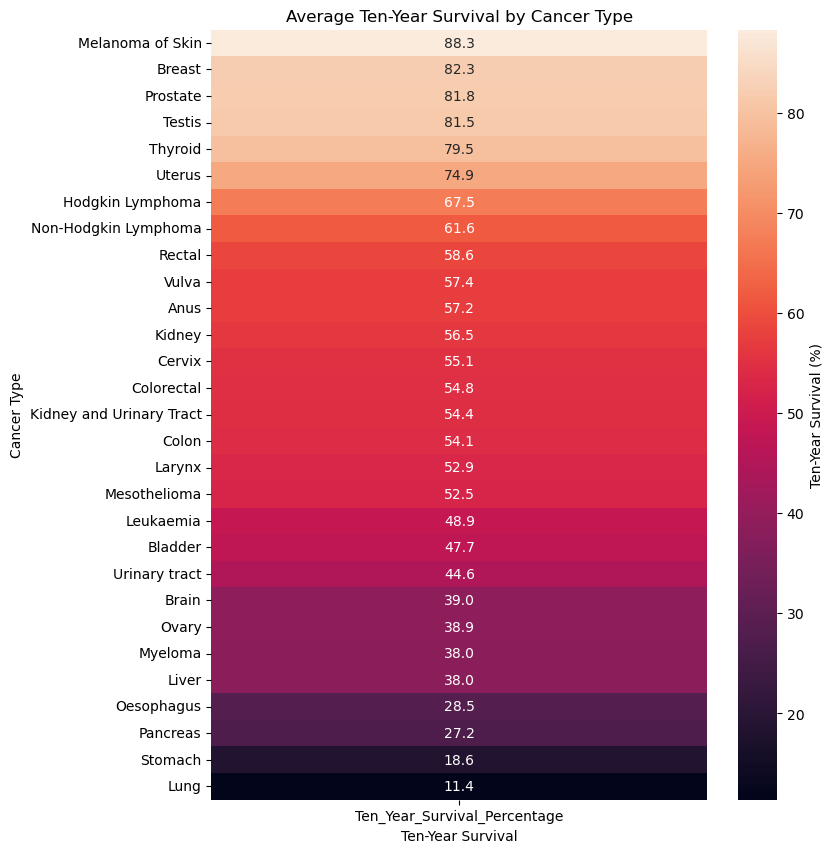

In [6]:
        # Avg. Cancer type survival % after 10 years heatmap

pivot = cancer_df_clean.pivot_table(
    values="Ten_Year_Survival_Percentage",
    index="Cancer_Type",
    aggfunc="mean"
)

pivot = pivot.sort_values("Ten_Year_Survival_Percentage", ascending=False)

plt.figure(figsize=(8, 10))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="rocket", cbar_kws={"label": "Ten-Year Survival (%)"})
plt.title("Average Ten-Year Survival by Cancer Type")
plt.ylabel("Cancer Type")
plt.xlabel("Ten-Year Survival")
plt.show()

<Axes: >

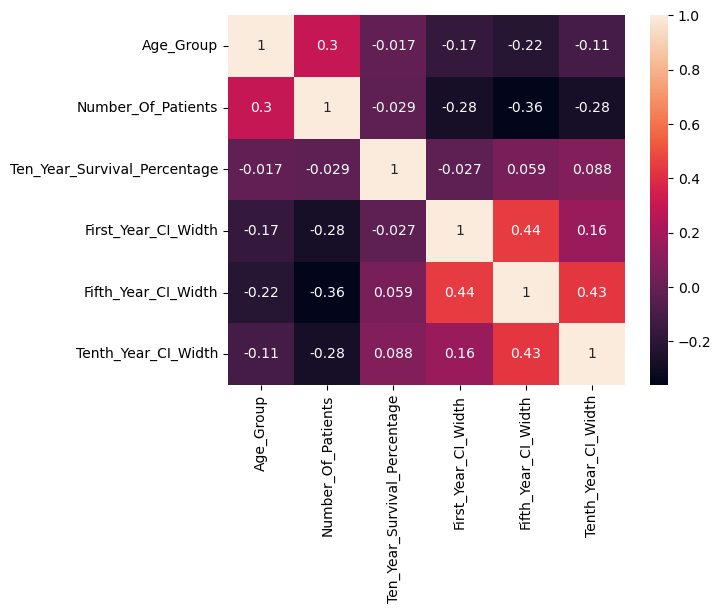

In [7]:
sns.heatmap(cancer_df_clean.corr(numeric_only=True), annot=True)

In [8]:
        # Creating XGBRegressor model

    ## Defining features and target

X = cancer_df_clean.drop('Ten_Year_Survival_Percentage', axis=1)
y = cancer_df_clean['Ten_Year_Survival_Percentage']

    ## Creating ColumnTransformer preprocessor for num. and cat. features (OneHot, Scaler)

features_cat = X[['Cancer_Type','Gender','Age_Group','Age_Standardized']].columns.tolist()

features_num = X[['First_Year_CI_Width','Fifth_Year_CI_Width','Tenth_Year_CI_Width']].columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), features_num),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), features_cat)
    ])


print("Value counts: ", cancer_df_clean.value_counts())

    ## Defining pipeline

pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', XGBRegressor(random_state=42))
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

print("Pipeline with no hyperparameter tuning...")
pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)

print(f"R² Score: {r2_score(y_test, y_pred):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

Value counts:  Cancer_Type    Gender   Age_Group  Age_Standardized  Number_Of_Patients  Ten_Year_Survival_Percentage  First_Year_CI_Width  Fifth_Year_CI_Width  Tenth_Year_CI_Width
Vulva          Women    True       15-99             9444                52.55                         1.6                  3.1                  4.0                    1
Anus           Men      False      15-44             261                 68.40                         7.5                  12.6                 27.9                   1
                                   15-99             3429                52.80                         2.9                  4.7                  8.9                    1
Urinary tract  Women    False      55-64             526                 52.55                         7.6                  10.3                 4.0                    1
                                   45-54             141                 52.55                         16.3                 2.1             

In [25]:
        # Creating and refining hyper-parameter grid for GridSearchCV

    ## Hyper-parameter grid

param_grid = {
    'regressor__n_estimators': [100, 200, 300, 500],
    'regressor__max_depth': [3, 5, 10, 15],
    'regressor__learning_rate': [0.01, 0.1, 0.2],
    'regressor__colsample_bytree': [0.5, 0.8]
}

    ## GridSearchCV with pipeline

grid_search = GridSearchCV(
    pipeline,
    param_grid=param_grid,
    cv=10,
    scoring='neg_mean_squared_error',
    n_jobs=-1,
    verbose=3
)

grid_search.fit(X_train, y_train)

print("Best params: ", grid_search.best_params_)
print("Best estimator: ", grid_search.best_estimator_)
print("Best rmse: ", np.sqrt(np.abs(grid_search.best_score_)))

Fitting 10 folds for each of 96 candidates, totalling 960 fits
Best params:  {'regressor__colsample_bytree': 0.5, 'regressor__learning_rate': 0.1, 'regressor__max_depth': 5, 'regressor__n_estimators': 500}
Best estimator:  Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['First_Year_CI_Width',
                                                   'Fifth_Year_CI_Width',
                                                   'Tenth_Year_CI_Width']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['Cancer_Type', 'Gender',
                                                   'Age_Gro

In [26]:
        # Predictions and results

best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)

print(f"R² Score: {r2_score(y_test, y_pred):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

R² Score: 0.8088
RMSE: 10.4354


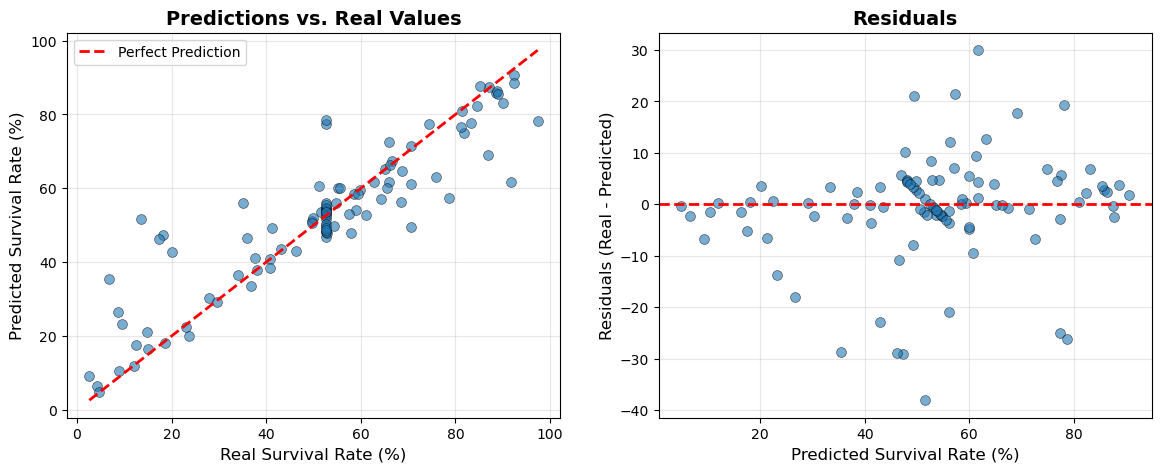

In [27]:


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter plot
axes[0].scatter(y_test, y_pred, alpha=0.6, s=50, edgecolors='k', linewidth=0.5)
axes[0].plot([y_test.min(), y_test.max()], 
             [y_test.min(), y_test.max()], 
             'r--', lw=2, label='Perfect Prediction')
axes[0].set_xlabel('Real Survival Rate (%)', fontsize=12)
axes[0].set_ylabel('Predicted Survival Rate (%)', fontsize=12)
axes[0].set_title('Predictions vs. Real Values', fontsize=14, fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=0.3)



residuals = y_test - y_pred
axes[1].scatter(y_pred, residuals, alpha=0.6, s=50, edgecolors='k', linewidth=0.5)
axes[1].axhline(y=0, color='r', linestyle='--', lw=2)
axes[1].set_xlabel('Predicted Survival Rate (%)', fontsize=12)
axes[1].set_ylabel('Residuals (Real - Predicted)', fontsize=12)
axes[1].set_title('Residuals', fontsize=14, fontweight='bold')
axes[1].grid(True, alpha=0.3)

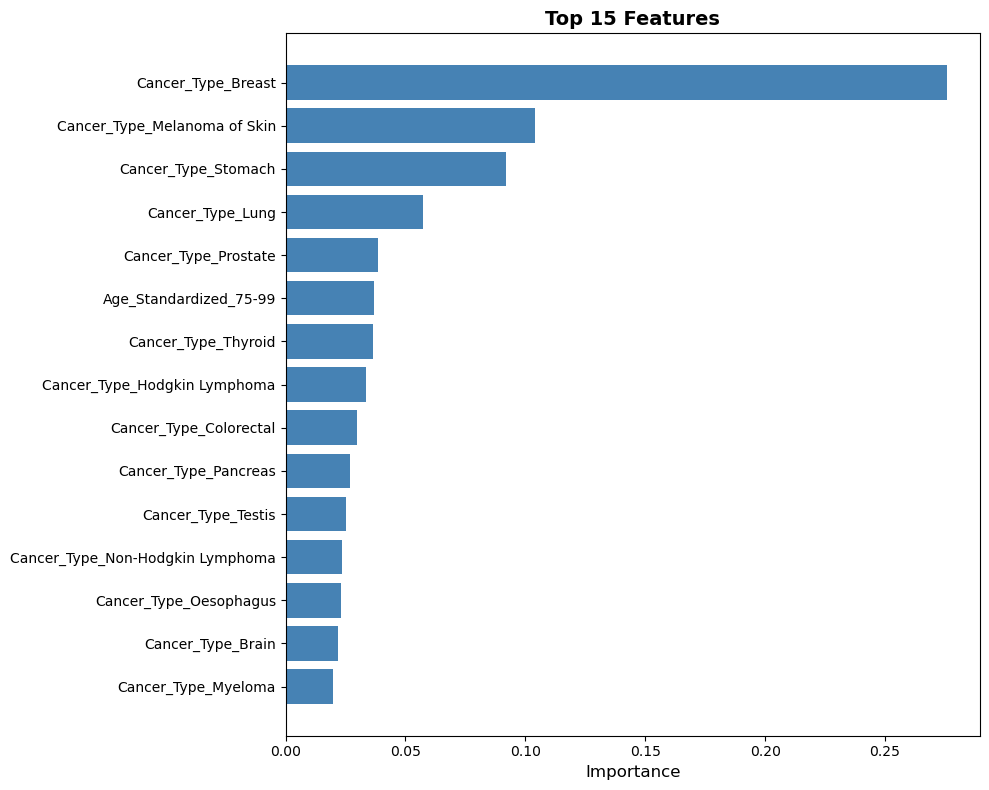

In [28]:
        # Obtaining feature importance

feature_names = (features_num + 
                 list(best_model.named_steps['preprocessor']
                     .named_transformers_['cat']
                     .get_feature_names_out(features_cat)))

importances = best_model.named_steps['regressor'].feature_importances_
feature_importance_df = pd.DataFrame({
    'feature': feature_names,
    'importance': importances
}).sort_values('importance', ascending=False)

top_n = 15
top_features = feature_importance_df.head(top_n)

plt.figure(figsize=(10, 8))
plt.barh(range(len(top_features)), top_features['importance'], color='steelblue')
plt.yticks(range(len(top_features)), top_features['feature'])
plt.xlabel('Importance', fontsize=12)
plt.title(f'Top {top_n} Features', fontsize=14, fontweight='bold')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()